In [1]:
#import necessary libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
#import os
#print (os.getcwd())

In [3]:
#print (os.listdir()) 

In [4]:
#import of dataset
churn_ds = pd.read_csv("Telecom_churn.csv")
#overview of the first 20 datas 
churn_ds.head(20) 

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.60,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.00,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.90,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.00,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.90,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability
5,0013-MHZWF,Female,23,No,3,Midpines,95345,37.581496,-119.972762,0,...,Credit Card,69.40,571.45,0.00,0,150.93,722.38,Stayed,NaN,NaN
6,0013-SMEOE,Female,67,Yes,0,Lompoc,93437,34.757477,-120.550507,1,...,Bank Withdrawal,109.70,7904.25,0.00,0,707.16,8611.41,Stayed,NaN,NaN
7,0014-BMAQU,Male,52,Yes,0,Napa,94558,38.489789,-122.270110,8,...,Credit Card,84.65,5377.80,0.00,20,816.48,6214.28,Stayed,NaN,NaN
8,0015-UOCOJ,Female,68,No,0,Simi Valley,93063,34.296813,-118.685703,0,...,Bank Withdrawal,48.20,340.35,0.00,0,73.71,414.06,Stayed,NaN,NaN
9,0016-QLJIS,Female,43,Yes,1,Sheridan,95681,38.984756,-121.345074,3,...,Credit Card,90.45,5957.90,0.00,0,1849.90,7807.80,Stayed,NaN,NaN


In [5]:
#check for infos of rows and cols as well datatype within data set
churn_ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   str    
 12  Pho

In [6]:
churn_ds.dtypes 

Customer ID                              str
Gender                                   str
Age                                    int64
Married                                  str
Number of Dependents                   int64
City                                     str
Zip Code                               int64
Latitude                             float64
Longitude                            float64
Number of Referrals                    int64
Tenure in Months                       int64
Offer                                    str
Phone Service                            str
Avg Monthly Long Distance Charges    float64
Multiple Lines                           str
Internet Service                         str
Internet Type                            str
Avg Monthly GB Download              float64
Online Security                          str
Online Backup                            str
Device Protection Plan                   str
Premium Tech Support                     str
Streaming 



                          columns  missing_column_count  missing_column_percentage data_type
                   Churn Category                  5174                  73.463013       str
                     Churn Reason                  5174                  73.463013       str
                            Offer                  3877                  55.047565       str
                    Internet Type                  1526                  21.666903       str
          Avg Monthly GB Download                  1526                  21.666903   float64
                  Online Security                  1526                  21.666903       str
                    Online Backup                  1526                  21.666903       str
           Device Protection Plan                  1526                  21.666903       str
             Premium Tech Support                  1526                  21.666903       str
                     Streaming TV                  1526             

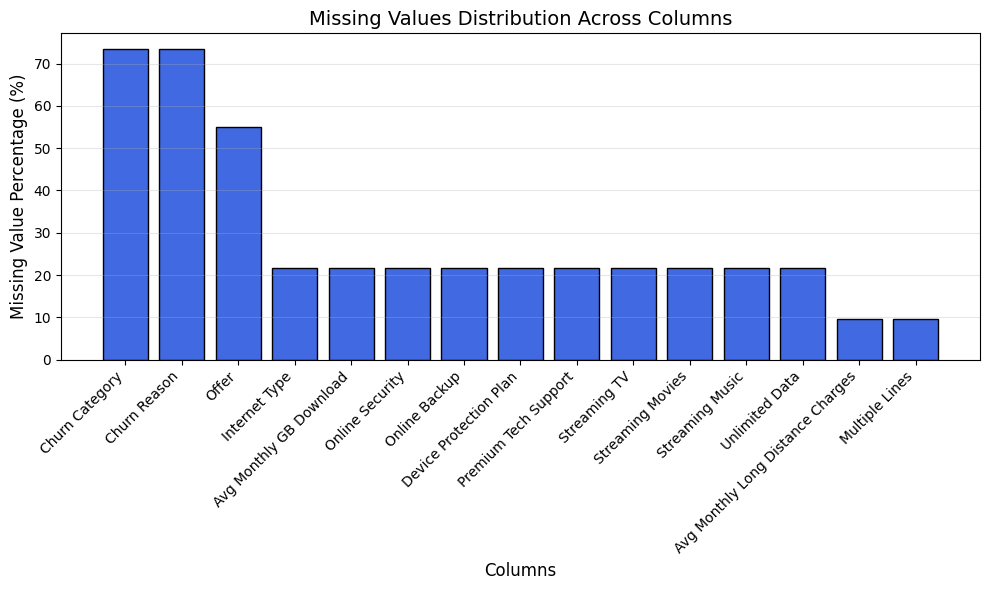

In [7]:
#building a dataframe for missing values in the dataset 
churnds_missing_rows = pd.DataFrame({'columns': churn_ds.columns,
                                 'missing_column_count': churn_ds.isnull().sum(),
                                 'missing_column_percentage': (churn_ds.isnull().sum()/len(churn_ds))*100,
                                 'data_type':  churn_ds.dtypes.values })
churnds_missing_rows =  churnds_missing_rows[churnds_missing_rows['missing_column_count'] > 0].sort_values('missing_column_count', ascending=False)

print("\n")
print(churnds_missing_rows.to_string(index=False))
print("\n") 
#plotting a bar chart to visualize percentage of missing values across the features in the dataset 
plt.figure(figsize=(10, 6))
plt.bar(churnds_missing_rows['columns'], churnds_missing_rows['missing_column_percentage'], color='#4169E1', edgecolor='black')
plt.xlabel('Columns', fontsize=12)
plt.ylabel('Missing Value Percentage (%)', fontsize=12)
plt.title('Missing Values Distribution Across Columns', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3) 
plt.tight_layout()
plt.show()  

## FIGURING OUT EMPTY COLUMNS 
This method was deployed to understand the empty columns, level and percentage of emptiness as well as its datatype  inorder to take a decision on how to fill the empty rows, a graphical illustration comparing the level of emptiness of each column was also initiated


In [8]:
churn_ds.columns = churn_ds.columns.str.replace(' ', '_')
print (churn_ds.columns) 

churn_ds.to_csv('Telecom_churn_cleaned.csv', index=False)
churn_ds.head()

Index(['Customer_ID', 'Gender', 'Age', 'Married', 'Number_of_Dependents',
       'City', 'Zip_Code', 'Latitude', 'Longitude', 'Number_of_Referrals',
       'Tenure_in_Months', 'Offer', 'Phone_Service',
       'Avg_Monthly_Long_Distance_Charges', 'Multiple_Lines',
       'Internet_Service', 'Internet_Type', 'Avg_Monthly_GB_Download',
       'Online_Security', 'Online_Backup', 'Device_Protection_Plan',
       'Premium_Tech_Support', 'Streaming_TV', 'Streaming_Movies',
       'Streaming_Music', 'Unlimited_Data', 'Contract', 'Paperless_Billing',
       'Payment_Method', 'Monthly_Charge', 'Total_Charges', 'Total_Refunds',
       'Total_Extra_Data_Charges', 'Total_Long_Distance_Charges',
       'Total_Revenue', 'Customer_Status', 'Churn_Category', 'Churn_Reason'],
      dtype='str')


,Customer_ID,Gender,Age,Married,Number_of_Dependents,City,Zip_Code,Latitude,Longitude,Number_of_Referrals,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [9]:
#filling empty up object type columns empty rows
churn_ds.fillna({'Churn_Reason':'Not Applicable'},
                 #'Churn_Category':'Not Applicable'}, 
                inplace=True)
churn_ds.fillna({'Churn_Category':'Not Applicable'},inplace = True)
churn_ds.fillna({'Offer':'No Offer'}, inplace=True)
churn_ds.fillna({'Internet_Type':'Not Specified'}, inplace=True)
churn_ds.fillna({'Online_Security':'Missing'},inplace=True) 
churn_ds.fillna({'Online_Backup':'Missing'}, inplace=True) 
churn_ds.fillna({'Device_Protection_Plan':'Missing'}, inplace= True)
churn_ds.fillna({'Premium_Tech_Support':'Missing'}, inplace=True)
churn_ds.fillna({'Streaming_TV':'Missing'}, inplace=True) 
churn_ds.fillna({'Streaming_Movies':'Missing'}, inplace=True)
churn_ds.fillna({'Streaming_Music':'Missing'}, inplace=True)
churn_ds.fillna({'Unlimited_Data':'Missing'},inplace=True)
churn_ds.fillna ({'Multiple_Lines':'Missing'},inplace=True)

,Customer_ID,Gender,Age,Married,Number_of_Dependents,City,Zip_Code,Latitude,Longitude,Number_of_Referrals,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.60,593.30,0.00,0,381.51,974.81,Stayed,Not Applicable,Not Applicable
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.00,542.40,38.33,10,96.21,610.28,Stayed,Not Applicable,Not Applicable
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.90,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.00,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.90,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,9987-LUTYD,Female,20,No,0,La Mesa,91941,32.759327,-116.997260,0,...,Credit Card,55.15,742.90,0.00,0,606.84,1349.74,Stayed,Not Applicable,Not Applicable
7039,9992-RRAMN,Male,40,Yes,0,Riverbank,95367,37.734971,-120.954271,1,...,Bank Withdrawal,85.10,1873.70,0.00,0,356.40,2230.10,Churned,Dissatisfaction,Product dissatisfaction
7040,9992-UJOEL,Male,22,No,0,Elk,95432,39.108252,-123.645121,0,...,Credit Card,50.30,92.75,0.00,0,37.24,129.99,Joined,Not Applicable,Not Applicable
7041,9993-LHIEB,Male,21,Yes,0,Solana Beach,92075,33.001813,-117.263628,5,...,Credit Card,67.85,4627.65,0.00,0,142.04,4769.69,Stayed,Not Applicable,Not Applicable


In [10]:
churn_ds.isnull().sum()

Customer_ID                             0
Gender                                  0
Age                                     0
Married                                 0
Number_of_Dependents                    0
City                                    0
Zip_Code                                0
Latitude                                0
Longitude                               0
Number_of_Referrals                     0
Tenure_in_Months                        0
Offer                                   0
Phone_Service                           0
Avg_Monthly_Long_Distance_Charges     682
Multiple_Lines                          0
Internet_Service                        0
Internet_Type                           0
Avg_Monthly_GB_Download              1526
Online_Security                         0
Online_Backup                           0
Device_Protection_Plan                  0
Premium_Tech_Support                    0
Streaming_TV                            0
Streaming_Movies                  

In [11]:
churn_ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer_ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number_of_Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip_Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number_of_Referrals                7043 non-null   int64  
 10  Tenure_in_Months                   7043 non-null   int64  
 11  Offer                              7043 non-null   str    
 12  Pho

## FILLING EMPTY ROWS 
The object-type columns were handled based on their business context. Columns such as **Churn Category** and **Churn Reason** were filled with **Non Applicable** as these are columns only applicable to those that has churned, while the column **Offer** which is also an object-type column  renamed to **Non Offer**. All other object-type columns with the missing values were filled with  **Missing** to distinguish available data category values. The numerical columns with the missing values such as **Avg Monthly GB Download** and **Avg Monthly Long Distance Charges** would go through imputation comparison whose root mean square error would be measured, and the imputation with the least error would be inputed into the missing rows. 

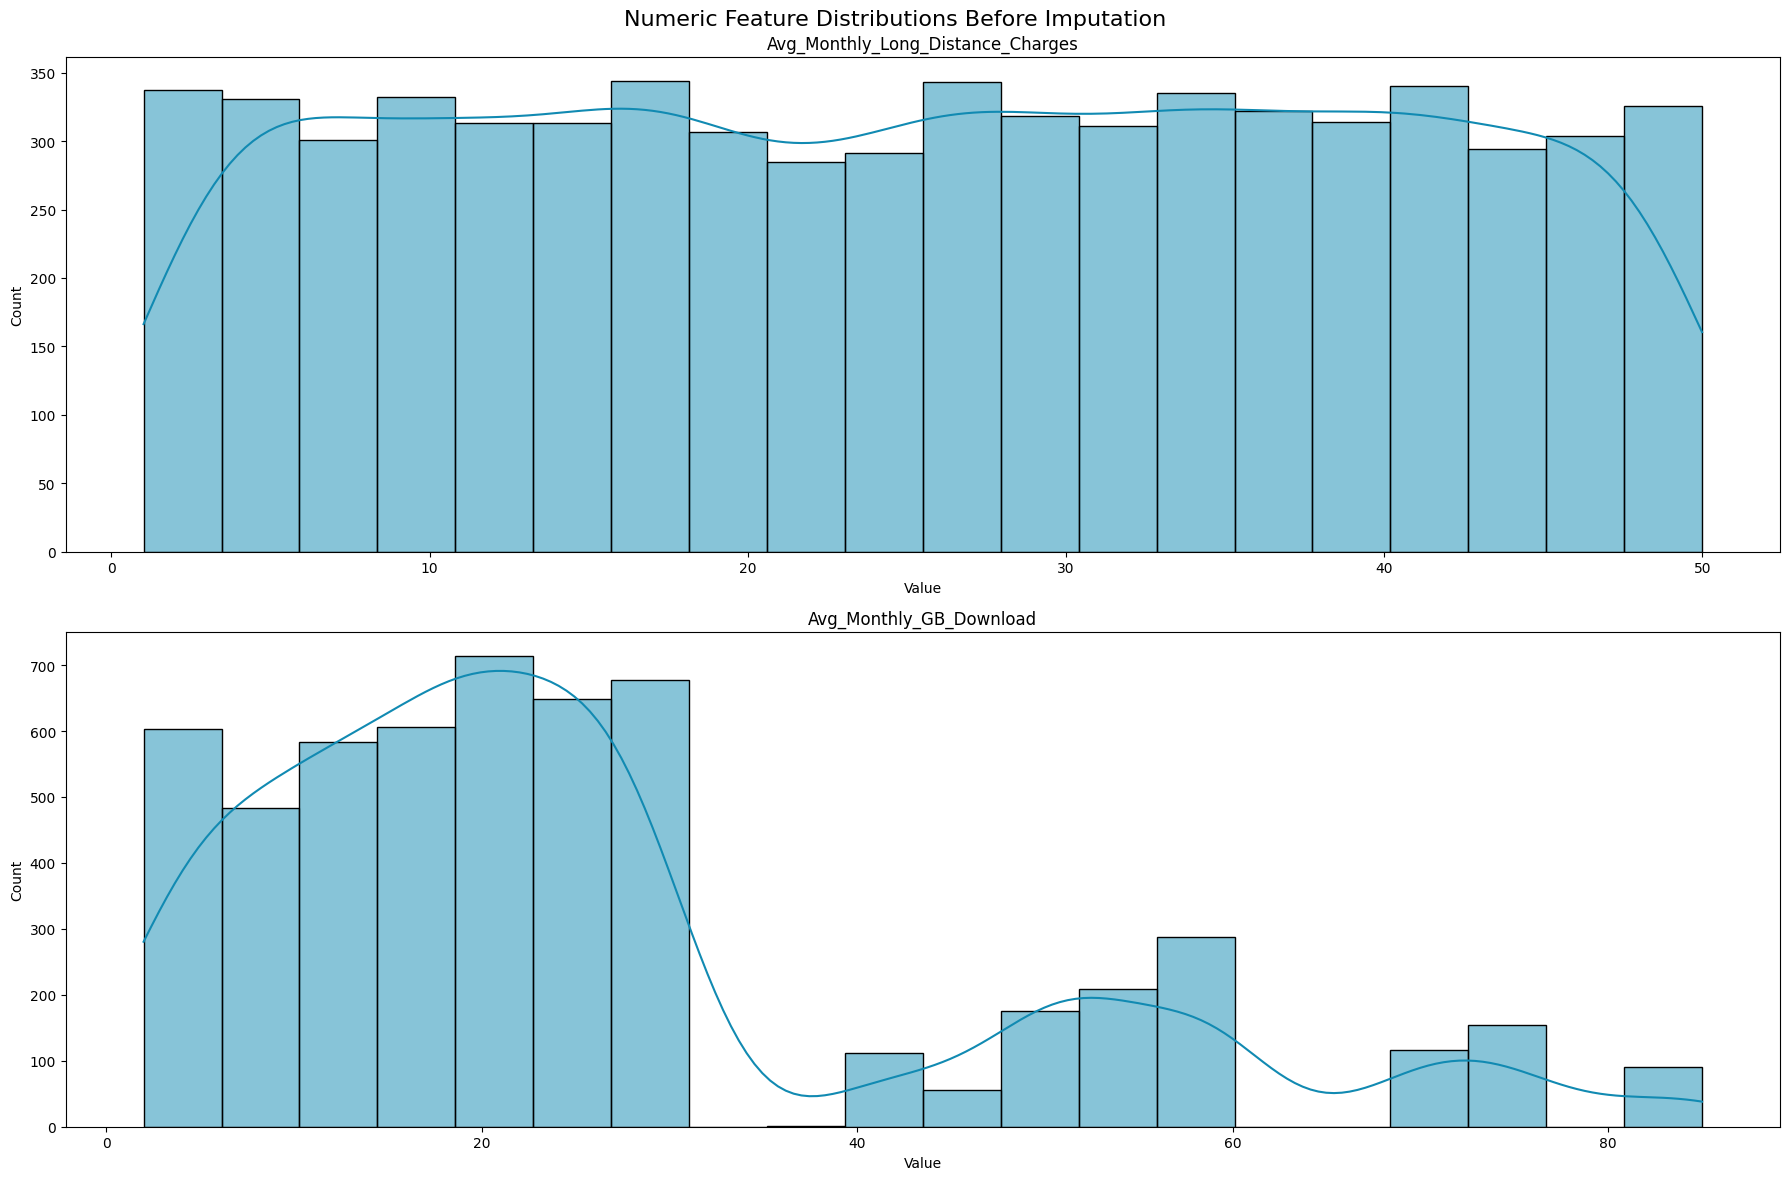

In [12]:
#classifying just numerical columns 
numerical_missing_features = ["Avg_Monthly_Long_Distance_Charges", "Avg_Monthly_GB_Download"]
#plotting histogram to understand distribution of dataset
#plotting 2 columns and 1 rows
fig, axes = plt.subplots(2, 1, figsize=(18, 12))
fig.suptitle('Numeric Feature Distributions Before Imputation', fontsize=16)

for axis, feature in zip(axes.flatten(), numerical_missing_features):
    sns.histplot(churn_ds[feature], bins=20, kde=True, ax=axis, color='#118ab2')
    axis.set_title(feature)
    axis.set_xlabel('Value')
    axis.set_ylabel('Count')

#axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show() 

## UNDERSTANDING THE NUMERICAL COLUMNS WITH MISSING ROWS KDE CURVE AND IMPUTATION METHOD 
These histograms + KDE curves help us visually check distribution shape for each Missing numeric column before imputation. Here, the plots for **Avg_Monthly_Long_Distance_Charges** look mostly smooth and not heavily skewed, while the **Avg_Monthly_GB_Download** Strongly (or heavily) right-skewed with evidence of multiple modes (multimodal), these supports using a model-based imputer that can preserve relationships between variables instead of injecting one repeated constant value (mean/median imputation method). Four different imputation methods are been compared, then we select  the one with the least error. 

In [13]:
numeric_missing_features = churn_ds.select_dtypes(include=['float64', 'int64']).columns  

Imputation method comparison using masked observed values:
Method        RMSE
  MICE  304.383106
   KNN  357.511373
  Mean 1073.660715
Median 1121.538142


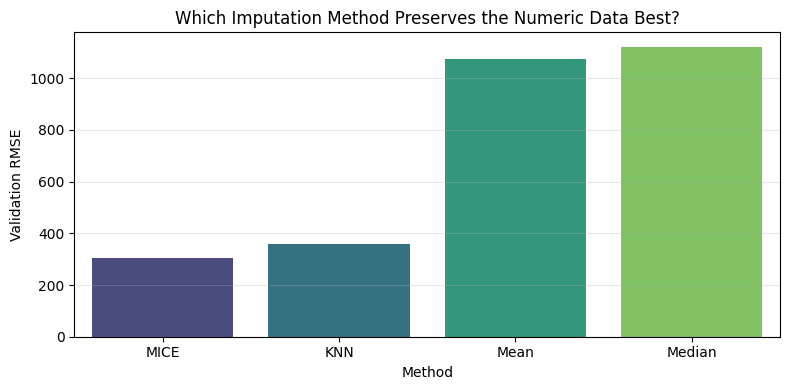

In [14]:
#import of necessary libraries for imputation
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer 
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import  mean_squared_error

#testing a comparison between empty rows imputations to know which is best suited 
comparison_source = churn_ds[numeric_missing_features].copy()  
observed_positions = np.argwhere(comparison_source.notna().to_numpy())
rng = np.random.default_rng(42)
mask_size = max(1, int(len(observed_positions) * 0.1))
selected_positions = observed_positions[rng.choice(len(observed_positions), size=mask_size, replace=False)]
validation_mask = pd.DataFrame(False, index=comparison_source.index, columns=comparison_source.columns)
for row_idx, col_idx in selected_positions:
    validation_mask.iat[row_idx, col_idx] = True

masked_data = comparison_source.mask(validation_mask)
scaler = StandardScaler()
scaled_masked = pd.DataFrame(
    scaler.fit_transform(masked_data),
    columns=numeric_missing_features,
    index=masked_data.index
)

imputer_trials = {
    'Mean': SimpleImputer(strategy='mean'),
    'Median': SimpleImputer(strategy='median'),
    'KNN': KNNImputer(n_neighbors=5, weights='distance'),
    'MICE': IterativeImputer(random_state=42, max_iter=20)
}

comparison_rows = []
validation_mask_array = validation_mask.to_numpy()
actual_values = comparison_source.to_numpy()[validation_mask_array]

for method_name, imputer in imputer_trials.items():
    imputed_scaled = pd.DataFrame(
        imputer.fit_transform(scaled_masked),
        columns=numeric_missing_features,
        index=scaled_masked.index
    )
    imputed_values = pd.DataFrame(
        scaler.inverse_transform(imputed_scaled),
        columns=numeric_missing_features,
        index=scaled_masked.index
    )

    predicted_values = imputed_values.to_numpy()[validation_mask_array]
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))

    comparison_rows.append({
        'Method': method_name,
        'RMSE': rmse
    })

comparison_results = pd.DataFrame(comparison_rows).sort_values('RMSE').reset_index(drop=True)
print('Imputation method comparison using masked observed values:')
print(comparison_results.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=comparison_results, x='Method', y='RMSE', hue='Method', palette='viridis', legend=False)
plt.title('Which Imputation Method Preserves the Numeric Data Best?')
plt.xlabel('Method')
plt.ylabel('Validation RMSE')
plt.grid(axis='y', alpha=0.3)  
plt.tight_layout()
plt.show() 


### SUMMARY OF THE ABOVE 
The above was the comparison between the four key choice of imputations and a result of how they perform filling in the missing values. A validation trick was deployed which required known values been hidden then imputation and a measure of the root mean square error(RMSE). The imputation with the lowest error is best fit for the data set 
**RESULT ANALYSIS**:
- **MICE**: By far the best performing imputation method with the least root mean square error 
- **KNN**: Its performance was relatively decent with  an error distance not to far off that of mice 
- **MEAN/MEDIAN**: Both were by a distance the worst performing imputation methods with the highest measurable errors. 

So as earlier stated the the imputation with the lowest rmse is best fit for the model so due to this reason the **MICE** imputation method is the top choice for imputation. 

In [15]:
churn_ds['Age'].unique()

array([37, 46, 50, 78, 75, 23, 67, 52, 68, 43, 47, 25, 58, 32, 39, 72, 79,
       26, 30, 22, 34, 42, 64, 48, 28, 33, 31, 60, 69, 20, 57, 19, 38, 54,
       35, 51, 66, 61, 24, 55, 59, 71, 49, 40, 21, 45, 29, 62, 76, 77, 73,
       41, 56, 80, 63, 53, 44, 70, 74, 36, 27, 65])

In [16]:
#categorizing the missing cols into the variable missing_cols
missing_features =  ["Avg_Monthly_Long_Distance_Charges", "Avg_Monthly_GB_Download"]

numeric_data = churn_ds[missing_features]

#standization of the scalar 
numeric_scaler = StandardScaler()
scaled_numeric = pd.DataFrame(
    numeric_scaler.fit_transform(numeric_data),
    columns=missing_features,
    index=churn_ds.index
) 
#implementation of the mice imputation method
mice_imputer = IterativeImputer(random_state=42, max_iter=20)
imputed_scaled_numeric = pd.DataFrame(
    mice_imputer.fit_transform(scaled_numeric),
    columns= missing_features,
    index=churn_ds.index
)
#reversal of the standization of the scalar into what it was before and clean of the trap label
churn_ds_imputed = churn_ds.copy()
imputed_numeric = pd.DataFrame(
    numeric_scaler.inverse_transform(imputed_scaled_numeric),
    columns= missing_features,
    index=churn_ds.index
)

churn_ds_imputed[missing_features] = imputed_numeric  

print('Remaining missing values in numeric features after MICE:')
print(churn_ds_imputed[missing_features].isna().sum().to_string())
print('\nCleaned dataset:')
churn_ds_imputed.info() 

Remaining missing values in numeric features after MICE:
Avg_Monthly_Long_Distance_Charges    0
Avg_Monthly_GB_Download              0

Cleaned dataset:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer_ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number_of_Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip_Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number_of_Referrals                7043 no

In [17]:
churn_ds_imputed.isnull().sum() 

Customer_ID                          0
Gender                               0
Age                                  0
Married                              0
Number_of_Dependents                 0
City                                 0
Zip_Code                             0
Latitude                             0
Longitude                            0
Number_of_Referrals                  0
Tenure_in_Months                     0
Offer                                0
Phone_Service                        0
Avg_Monthly_Long_Distance_Charges    0
Multiple_Lines                       0
Internet_Service                     0
Internet_Type                        0
Avg_Monthly_GB_Download              0
Online_Security                      0
Online_Backup                        0
Device_Protection_Plan               0
Premium_Tech_Support                 0
Streaming_TV                         0
Streaming_Movies                     0
Streaming_Music                      0
Unlimited_Data           

## Check for Outliers : 
This involves checking the graphical distribution of each numerical column in order to determine appropriate outlier checking method and proper outlier sorting process. 

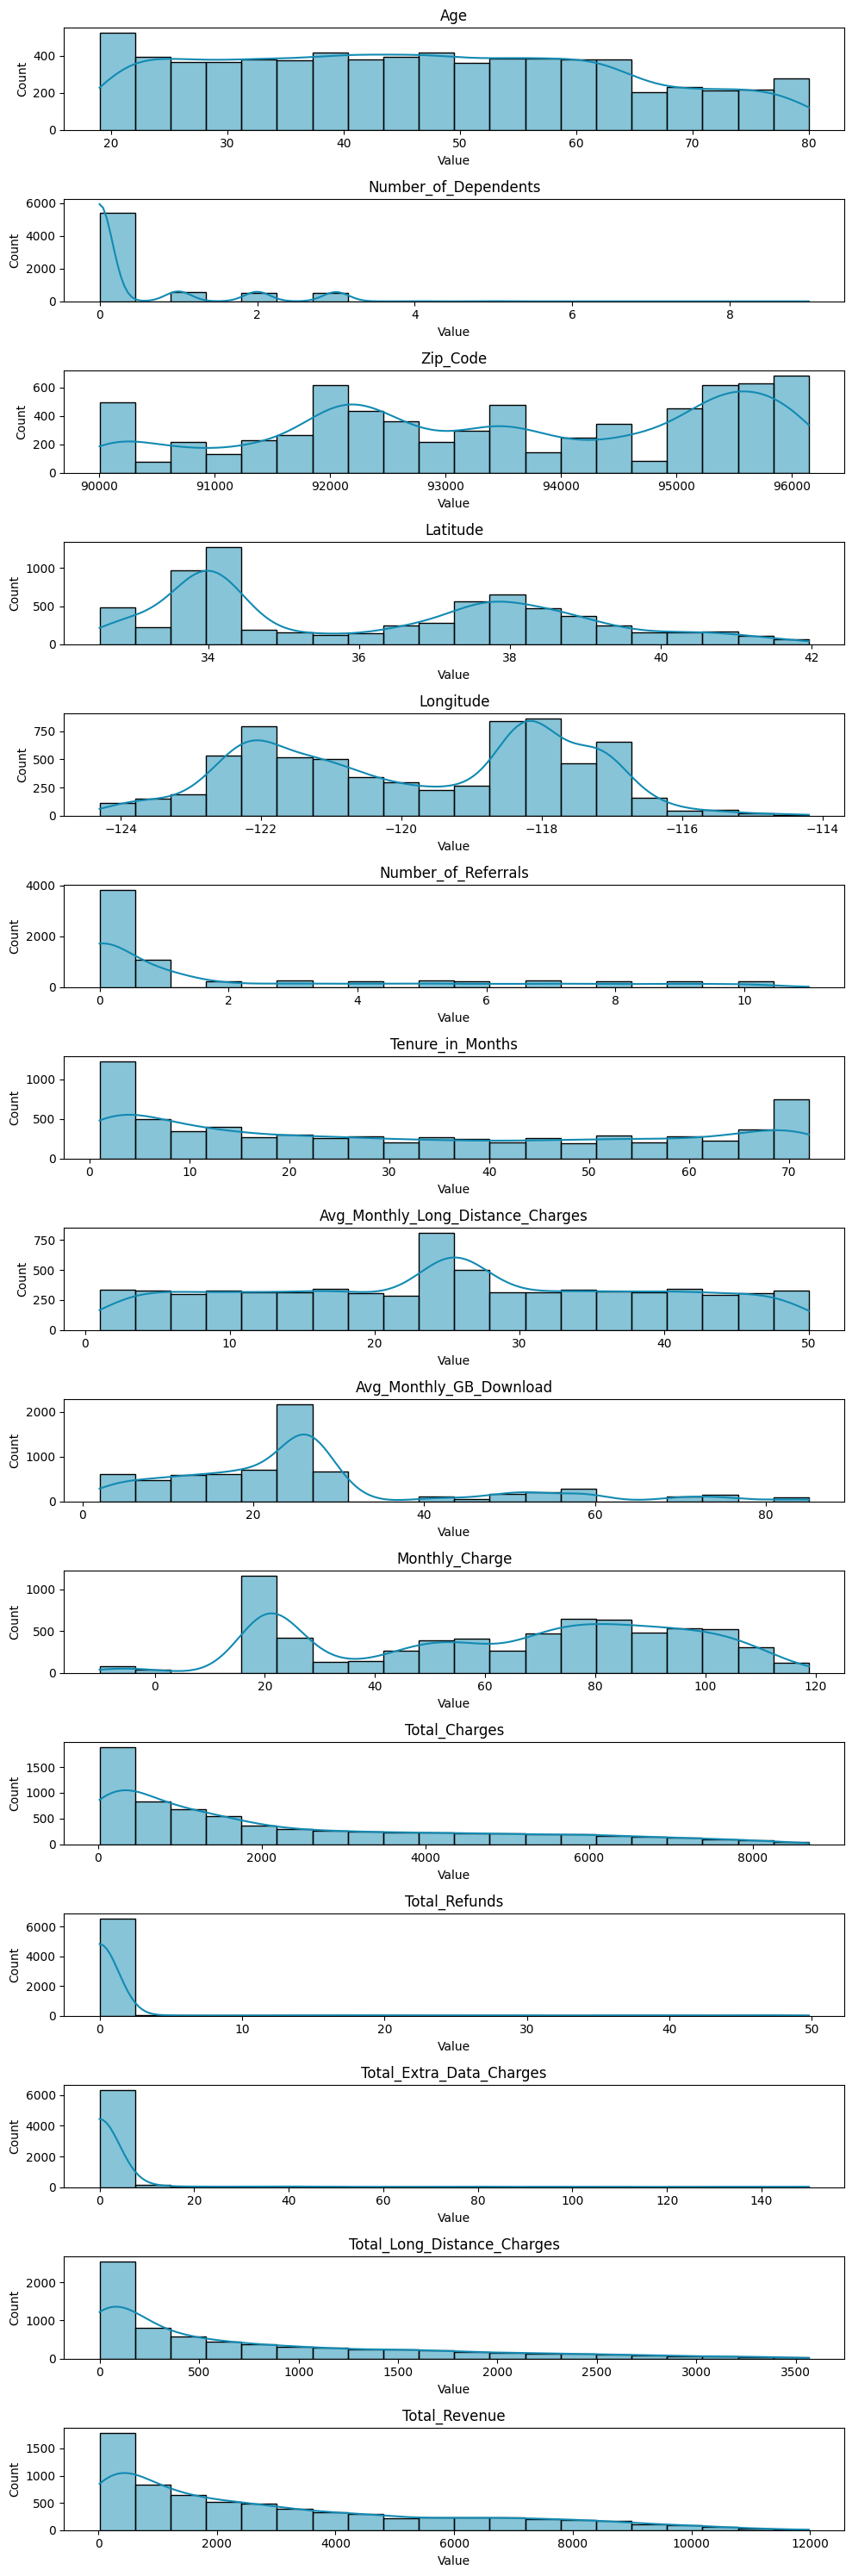

In [18]:
numeric_features = churn_ds_imputed.select_dtypes(include=np.number)
#plotting histogram to understand distribution of dataset
#plotting the entire numeric columns and 1 row
fig, axes = plt.subplots(len(numeric_features.columns), 1, figsize=(10, 30))
#fig.suptitle('Numeric Feature Distributions to detect outliers check method', fontsize=16)

for axis, feature in zip(axes.flatten(), numeric_features):
    sns.histplot(churn_ds_imputed[feature], bins=20, kde=True, ax=axis, color='#118ab2')
    axis.set_title(feature)
    axis.set_xlabel('Value')
    axis.set_ylabel('Count')

#axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()  

Skewed_cols = [ 'Number_of_Dependant',
     'Avg_Monthly_GB_Download',
    'Total_charges',
    'Total_Refunds',
    'Total_Extra_Data_Charges',
    'Total_Charges',
    'Total_Long_Distance_Charges',
    'Total_Revenue'
    ]  

    uniform_symmentrical_cols = [
    'Age',
    'Tenure_in_Months',
    'Avg_Monthly_Long_Distance_Charges']

multimodal = ['Zip_Code','Latitude','Longtitude', 'Number_of_Referral']

**Brief Explanation of Above:**

The graphical illustrations above show the distribution of each numerical column after imputation to identify potential outliers before further analysis. The **Age** and **Avg_Monthly_Long_Distance_Charges** columns are approximately and roughly uniform, as they appear fairly smooth without any noticeable skewness.

The **Latitude** and **Longitude** columns exhibit a bimodal distribution, while **Tenure_in_Months** displays a U-shaped distribution, Although **Zip_Code** shows multiple peaks, it is a geographical identifier and is therefore not interpreted as a continuous numerical distribution.

The remaining numerical columns are positively skewed to varying levels, with most observations concentrated at lower values and fewer observations extending towards the higher end of the distribution.


In [19]:
#skewed data's both slighly, moderately and highly skewed outliers check 
skewed_cols = ['Number_of_Dependents',
              'Avg_Monthly_GB_Download',
              'Total_Charges',
              'Total_Refunds',
              'Total_Extra_Data_Charges',
              'Total_Charges',
              'Total_Long_Distance_Charges',
               'Total_Revenue' ]

#num_cols = churn_ds_imputed[skewed_numeric_datas]
result =[]
for col in skewed_cols:
    Q1 = churn_ds_imputed[col].quantile(0.25)
    Q3 = churn_ds_imputed[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR 

    result.append({ 'columns': col,
                 'lower': lower,
                 'upper':upper
})     
Outlier_detected = pd.DataFrame (result) 
Outlier_detected  




,columns,lower,upper
0,Number_of_Dependents,0.0000,0.0000
1,Avg_Monthly_GB_Download,-3.0000,45.0000
2,Total_Charges,-4679.5250,8866.2750
3,Total_Refunds,0.0000,0.0000
4,Total_Extra_Data_Charges,0.0000,0.0000
5,Total_Charges,-4679.5250,8866.2750
6,Total_Long_Distance_Charges,-1610.2875,2871.9325
7,Total_Revenue,-5687.6925,11094.4475


In [20]:

churn_ds_imputed[skewed_cols].describe() 

,Number_of_Dependents,Avg_Monthly_GB_Download,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Charges,Total_Long_Distance_Charges,Total_Revenue
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.468692,26.188014,2280.381264,1.962182,6.860713,2280.381264,749.099262,3034.379056
std,0.962802,17.335266,2266.220462,7.902614,25.104978,2266.220462,846.660055,2865.204542
min,0.000000,2.000000,18.800000,0.000000,0.000000,18.800000,0.000000,21.360000
25%,0.000000,15.000000,400.150000,0.000000,0.000000,400.150000,70.545000,605.610000
50%,0.000000,25.833358,1394.550000,0.000000,0.000000,1394.550000,401.440000,2108.640000
75%,0.000000,27.000000,3786.600000,0.000000,0.000000,3786.600000,1191.100000,4801.145000
max,9.000000,85.000000,8684.800000,49.790000,150.000000,8684.800000,3564.720000,11979.340000


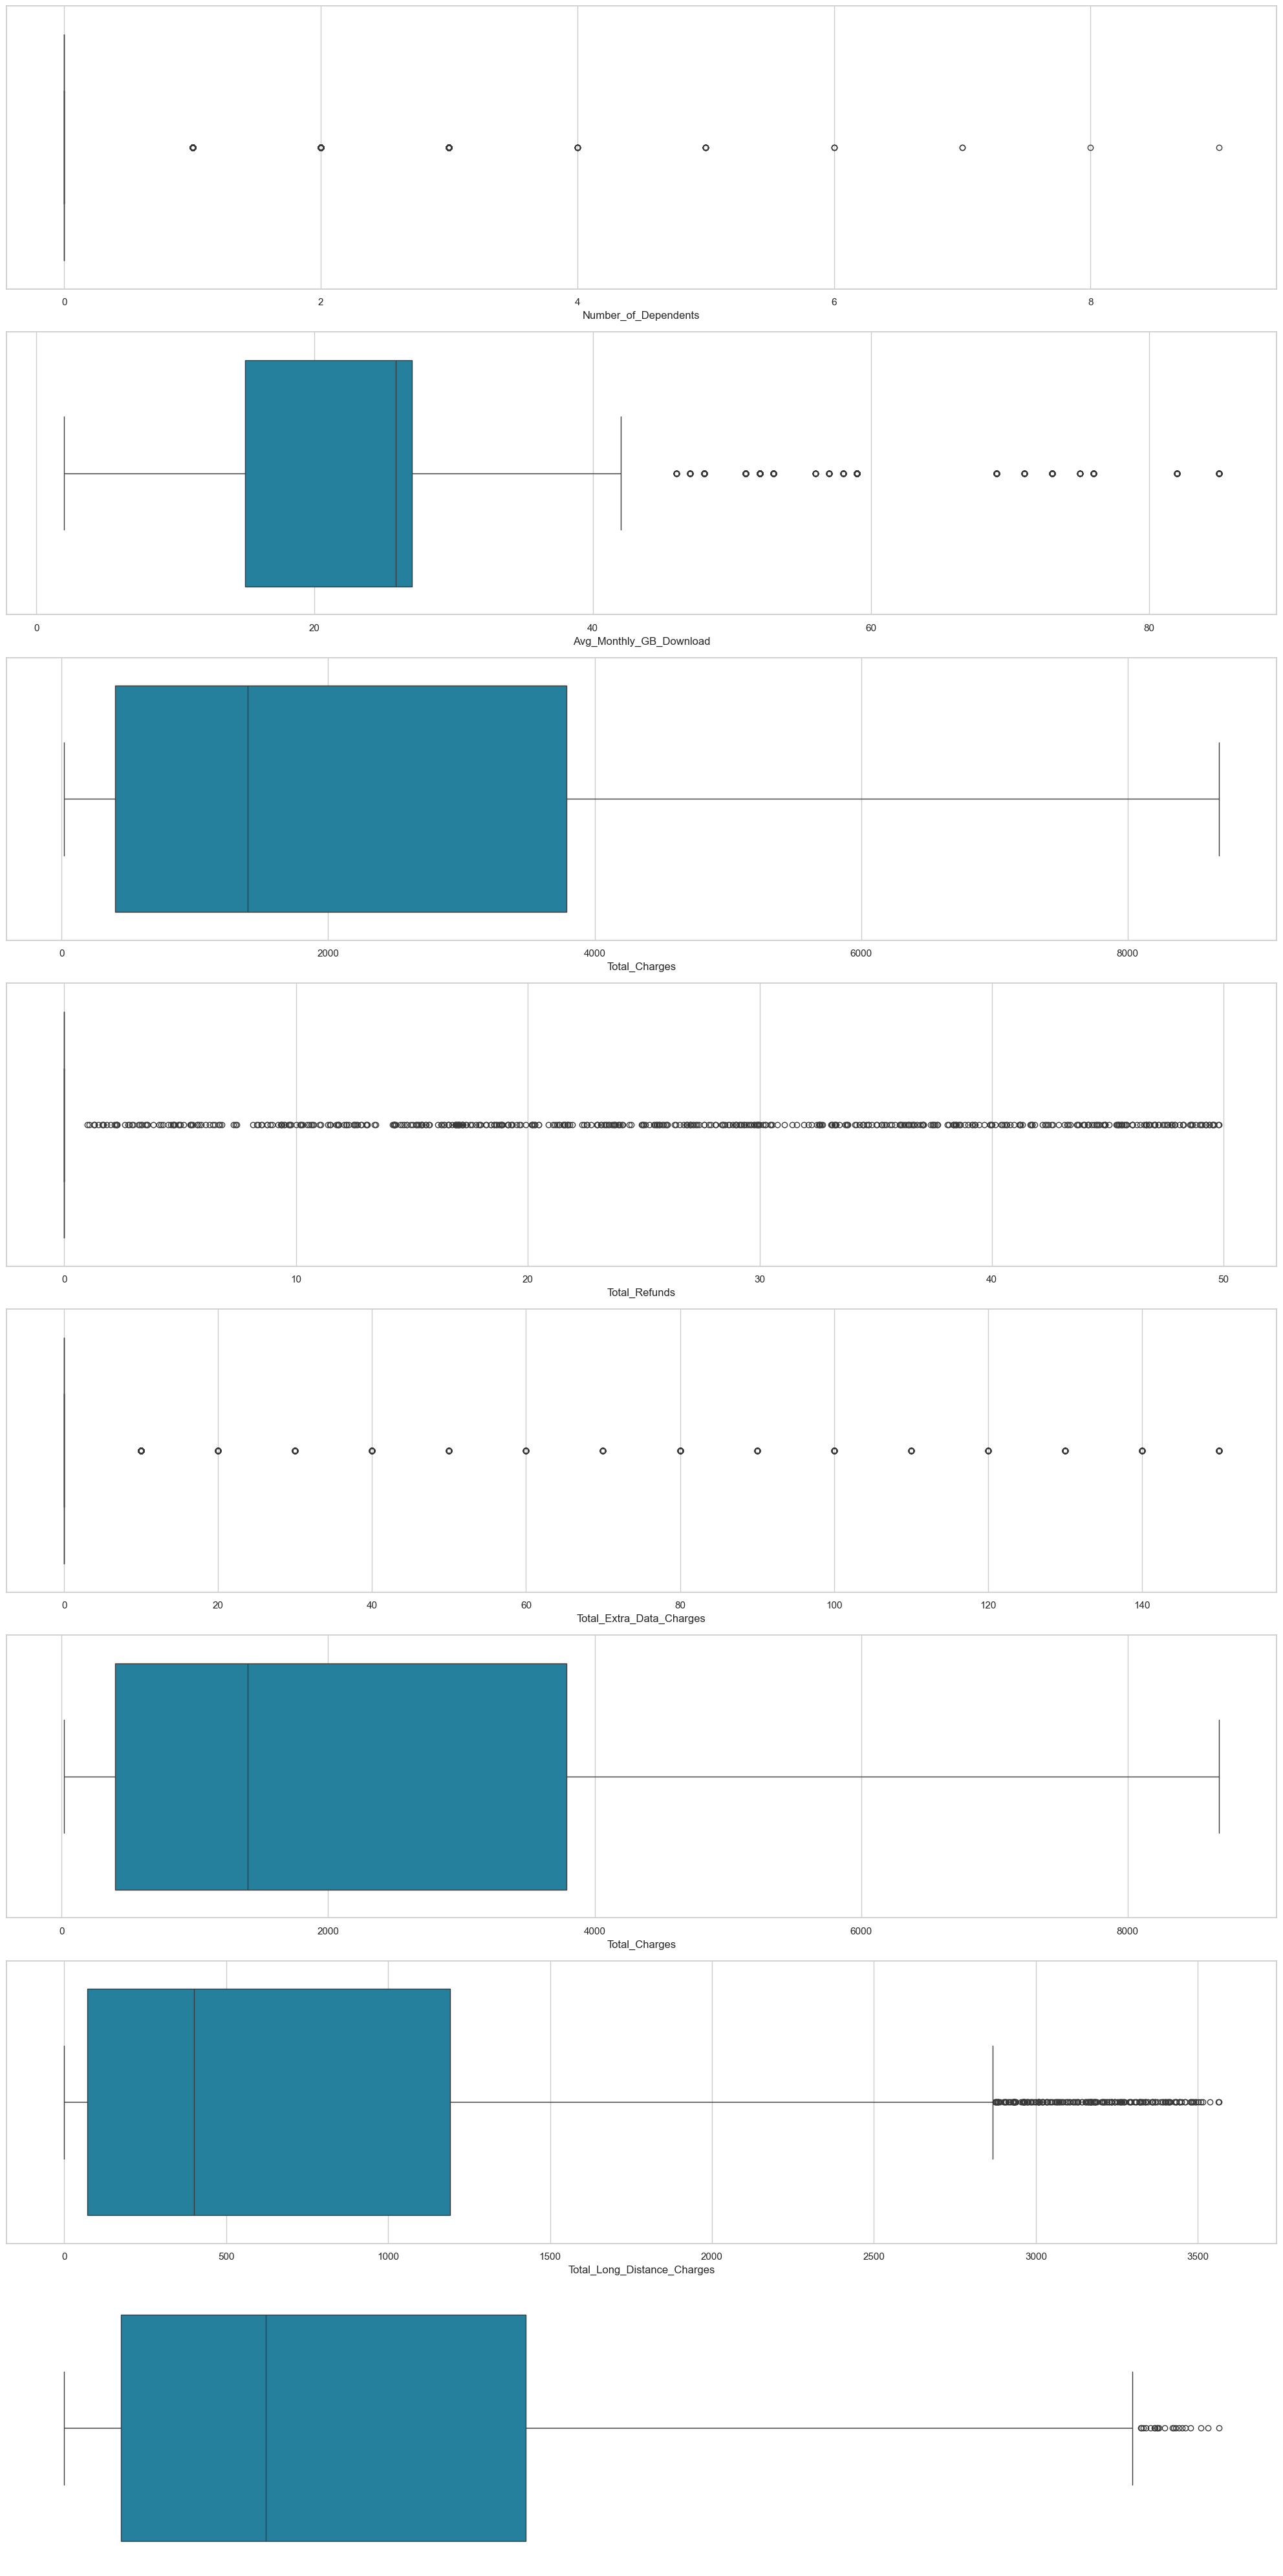

In [21]:
#splitting numerical columns into numeric_features
numeric_features = ['Number_of_Dependents',
              'Avg_Monthly_GB_Download',
              'Total_Charges',
              'Total_Refunds',
              'Total_Extra_Data_Charges',
              'Total_Charges',
              'Total_Long_Distance_Charges',
               'Total_Revenue']

 
#setting plot style
sns.set_theme(style="whitegrid")
primary_color = "#118ab2"

    # create a figure with 3 subplots (2 row, 3 columns)
fig, axes = plt.subplots(len(numeric_features), 1, figsize=(20, 40))
#fig.suptitle('outlier check for skewed data', fontsize=16)
#converts the 2x3 array into a 1D array
axes = axes.flatten()
for index, feature in enumerate(numeric_features): 
 sns.boxplot(x=churn_ds_imputed[feature], color=primary_color, ax=axes[index])
 

#hide unused plot
axes[-1].axis("off")
    # Display the charts
plt.tight_layout()
plt.show()  

In [22]:
#skewed data's both slighly, moderately and highly skewed outliers check 
skewed_cols = ['Number_of_Dependents',
              'Avg_Monthly_GB_Download',
              'Total_Charges',
              'Total_Refunds',
              'Total_Extra_Data_Charges',
              'Total_Charges',
              'Total_Long_Distance_Charges',
               'Total_Revenue' ]

#num_cols = churn_ds_imputed[skewed_numeric_datas]
result =[]
for col in skewed_cols:
    Q1 = churn_ds_imputed[col].quantile(0.25)
    Q3 = churn_ds_imputed[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR 

    result.append({ 'columns': col,
                 'lower': lower,
                 'upper':upper
})     
    Outlier_detected = pd.DataFrame (result) 
    Outlier_detected  
#clip datas into the lower and upper bounds to remove outliers from the dataset
    churn_ds_imputed[col] = churn_ds_imputed[col].clip(lower, upper)

In [23]:
#making use of percentile bound for the age column to detect outliers
lower = churn_ds_imputed['Age'].quantile(0.005)
upper = churn_ds_imputed['Age'].quantile(0.995)

age_outliers = churn_ds_imputed[
    (churn_ds_imputed['Age'] < lower) |
    (churn_ds_imputed['Age'] > upper)
]

age_outliers 


,Customer_ID,Gender,Age,Married,Number_of_Dependents,City,Zip_Code,Latitude,Longitude,Number_of_Referrals,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason


In [24]:
#making use of percentile bound for the Tenure_in_Months column to detect outliers
lower = churn_ds_imputed['Tenure_in_Months'].quantile(0.005)
upper = churn_ds_imputed['Tenure_in_Months'].quantile(0.995)
#setting boundaries for the Tenure_in_Months column to detect outliers
tenure_outliers = churn_ds_imputed[
    (churn_ds_imputed['Tenure_in_Months'] < lower) |
    (churn_ds_imputed['Tenure_in_Months'] > upper)]

tenure_outliers

,Customer_ID,Gender,Age,Married,Number_of_Dependents,City,Zip_Code,Latitude,Longitude,Number_of_Referrals,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason


In [26]:
churn_ds_imputed['Avg_Monthly_Long_Distance_Charges'].describe() 

count    7043.000000
mean       25.421296
std        13.495368
min         1.010000
25%        14.455000
50%        25.399646
75%        36.395000
max        49.990000
Name: Avg_Monthly_Long_Distance_Charges, dtype: float64

### OUTLIERS CHECKER AND HANDLING

The skewed numerical columns were examined for outliers using the **Interquartile Range (IQR)** method. This approach was adopted to identify extreme observations that could potentially influence the analysis.

Where outliers were detected, the values were clipped to their respective lower and upper bounds. This helped reduce the effect of extreme values while preserving the overall distribution of the data.

A percentile-based approach was also applied to the **Age** and **Tenure_in_Months** columns. However, no outliers were identified in either of these.

The remaining numerical columns, namely **Zip_Code**, **Latitude**, and **Longitude**, were excluded from the outlier detection process because they represent geographical information rather than continuous numerical measurements. As such, extreme values in these columns would goveback valid locations and not anomalies. 

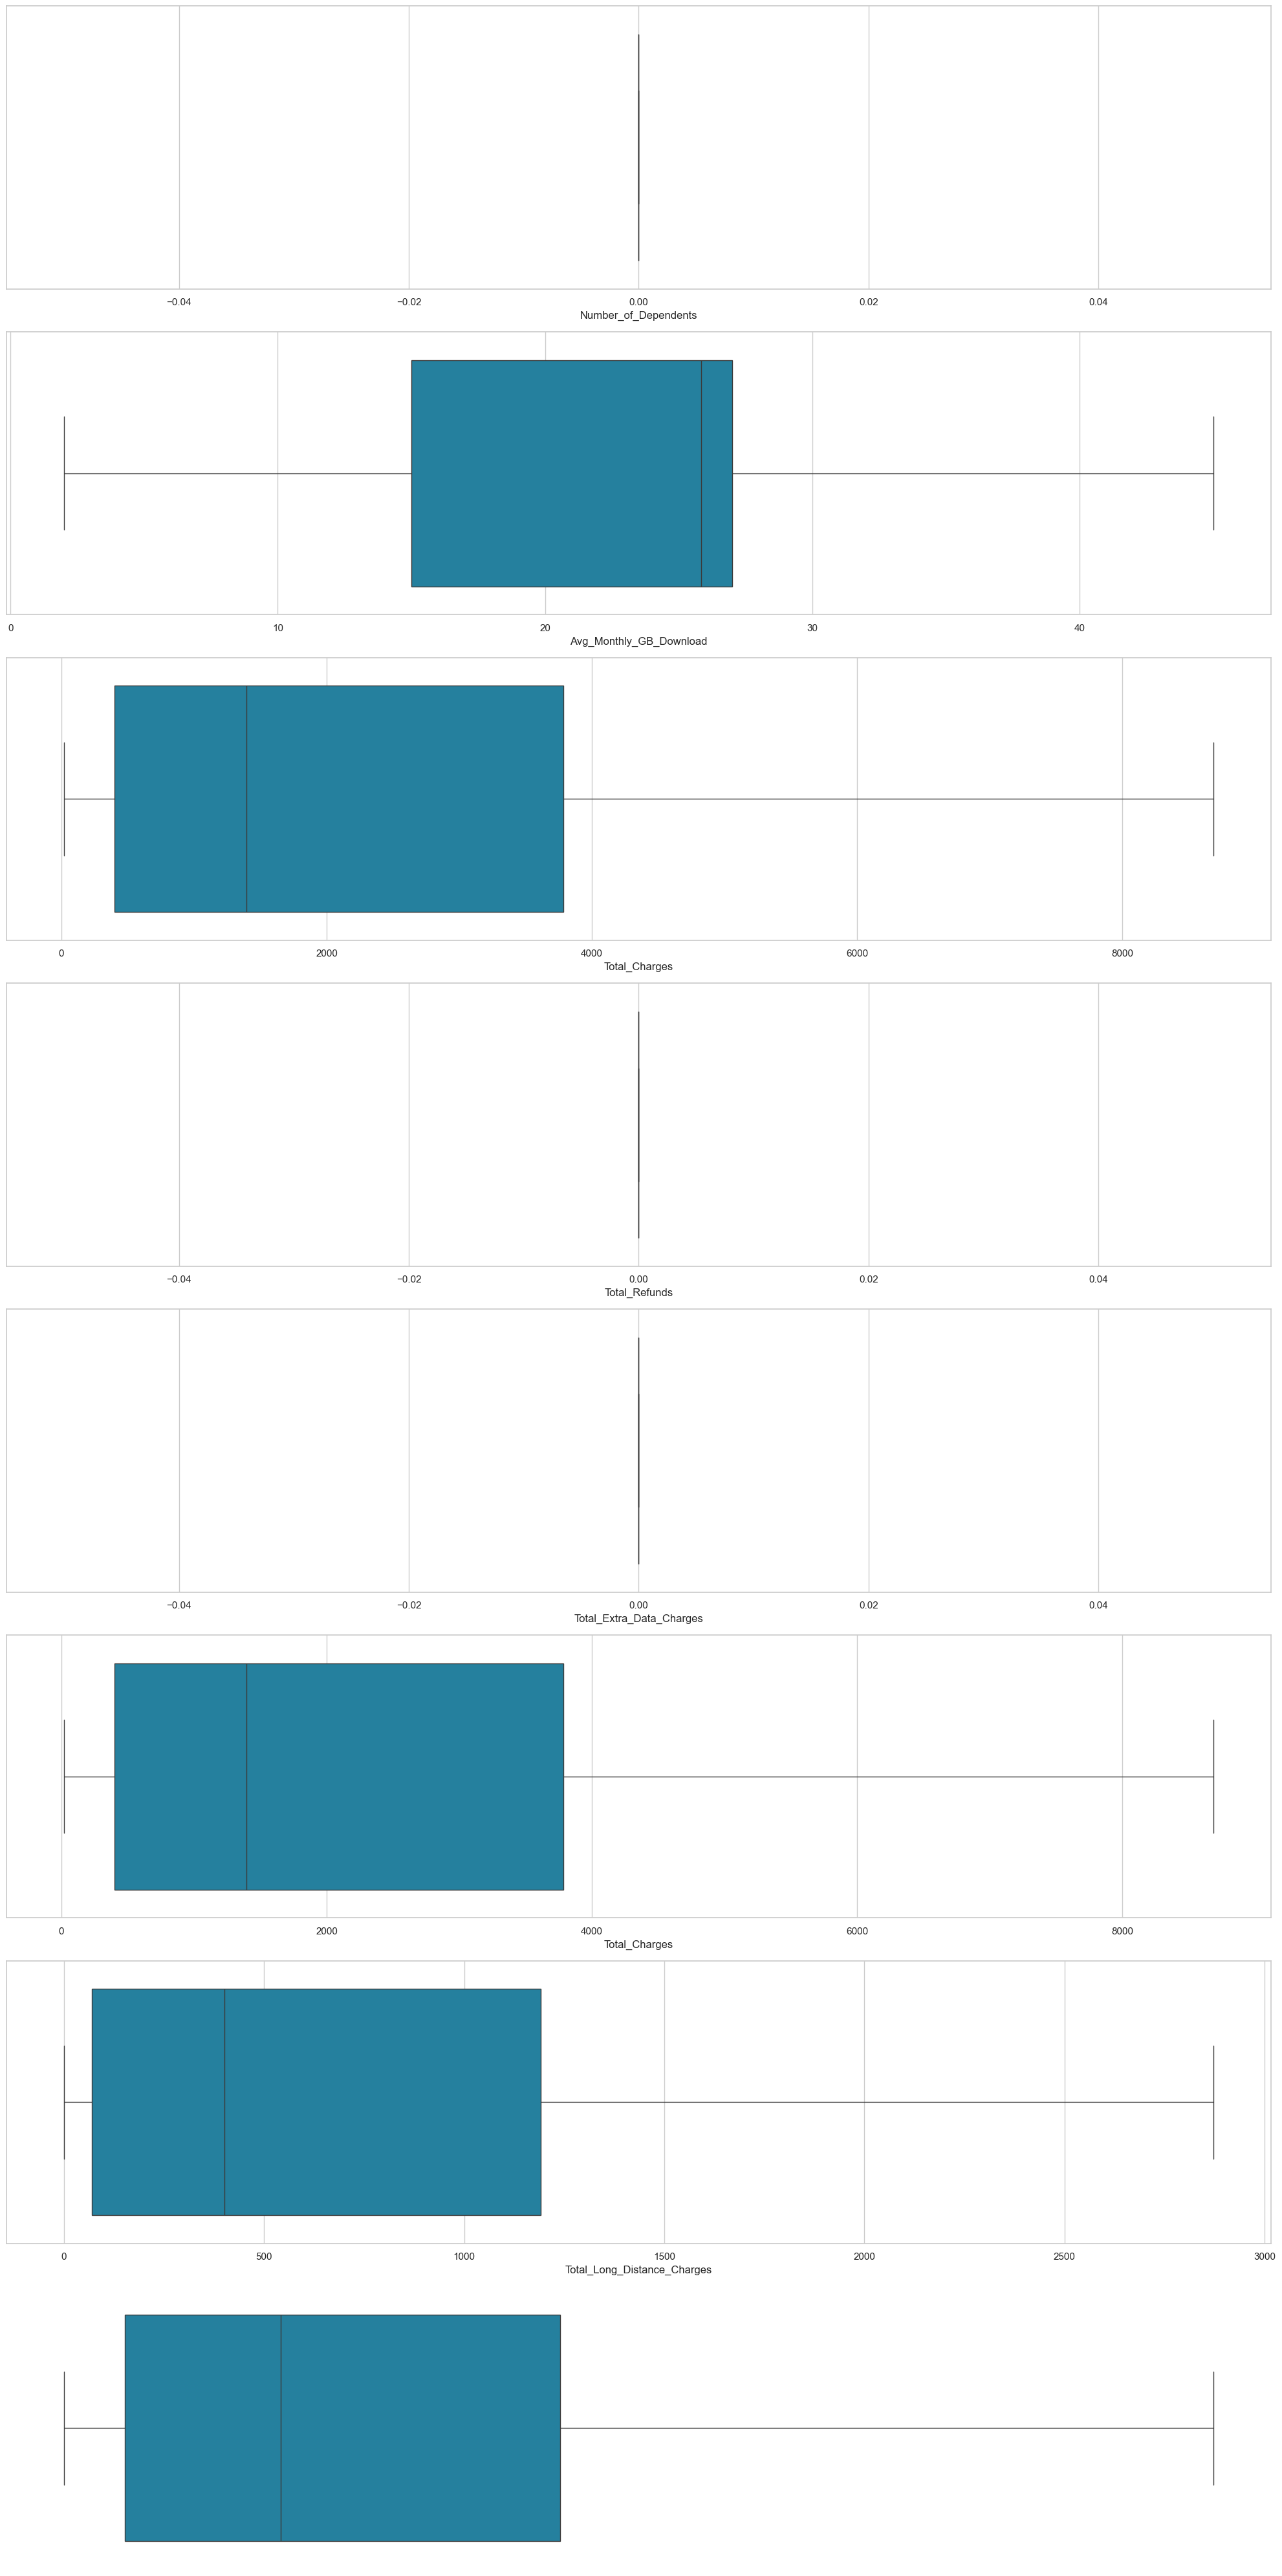

In [27]:
#splitting numerical columns into numeric_features
numeric_features = ['Number_of_Dependents',
              'Avg_Monthly_GB_Download',
              'Total_Charges',
              'Total_Refunds',
              'Total_Extra_Data_Charges',
              'Total_Charges',
              'Total_Long_Distance_Charges',
               'Total_Revenue']

 
#setting plot style
sns.set_theme(style="whitegrid")
primary_color = "#118ab2"

    # create a figure with 3 subplots (2 row, 3 columns)
fig, axes = plt.subplots(len(numeric_features), 1, figsize=(20, 40))
#fig.suptitle('outlier check for skewed data', fontsize=16)
#converts the 2x3 array into a 1D array
axes = axes.flatten()
for index, feature in enumerate(numeric_features): 
 sns.boxplot(x=churn_ds_imputed[feature], color=primary_color, ax=axes[index])
 

#hide unused plot
axes[-1].axis("off")
    # Display the charts
plt.tight_layout()
plt.show()  

In [28]:
churn_ds_imputed.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer_ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number_of_Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip_Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number_of_Referrals                7043 non-null   int64  
 10  Tenure_in_Months                   7043 non-null   int64  
 11  Offer                              7043 non-null   str    
 12  Pho

In [29]:
churn_ds_imputed.head(20)

,Customer_ID,Gender,Age,Married,Number_of_Dependents,City,Zip_Code,Latitude,Longitude,Number_of_Referrals,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.60,593.30,0.0,0,381.51,974.81,Stayed,Not Applicable,Not Applicable
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.00,542.40,0.0,0,96.21,610.28,Stayed,Not Applicable,Not Applicable
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.90,280.85,0.0,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.00,1237.85,0.0,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.90,267.40,0.0,0,22.14,289.54,Churned,Dissatisfaction,Network reliability
5,0013-MHZWF,Female,23,No,0,Midpines,95345,37.581496,-119.972762,0,...,Credit Card,69.40,571.45,0.0,0,150.93,722.38,Stayed,Not Applicable,Not Applicable
6,0013-SMEOE,Female,67,Yes,0,Lompoc,93437,34.757477,-120.550507,1,...,Bank Withdrawal,109.70,7904.25,0.0,0,707.16,8611.41,Stayed,Not Applicable,Not Applicable
7,0014-BMAQU,Male,52,Yes,0,Napa,94558,38.489789,-122.270110,8,...,Credit Card,84.65,5377.80,0.0,0,816.48,6214.28,Stayed,Not Applicable,Not Applicable
8,0015-UOCOJ,Female,68,No,0,Simi Valley,93063,34.296813,-118.685703,0,...,Bank Withdrawal,48.20,340.35,0.0,0,73.71,414.06,Stayed,Not Applicable,Not Applicable
9,0016-QLJIS,Female,43,Yes,0,Sheridan,95681,38.984756,-121.345074,3,...,Credit Card,90.45,5957.90,0.0,0,1849.90,7807.80,Stayed,Not Applicable,Not Applicable


In [30]:
churn_ds_imputed.to_csv("telecom_churndataset.csv", index=False) 

In [ ]:

#numeric_features = churn_ds_imputed.select_dtypes(include='number').columns
#print(numeric_features) 